# HW 1 Part D: SEIR model with births and deaths

**Model** (S, E, I, R are numbers of people; $N=2000$):
$$\frac{dS}{dt}=\mu N-\beta SI-\mu S,\qquad
\frac{dE}{dt}=\beta SI-(\sigma+\mu)E,\qquad
\frac{dI}{dt}=\sigma E-(\gamma+\mu)I,\qquad
\frac{dR}{dt}=\gamma I-\mu R$$

* $E$ = **exposed**: infected but not yet infectious (latent). $1/\sigma$ = mean latent period.
* $\mu$ = per-capita birth rate = per-capita death rate, so $1/\mu$ = mean lifespan.

**Solver.** Same hand-written RK4 and `simulate` driver as Parts A–C (`epimodels.py`); only a new right-hand side,
`seir_rhs`, was added. Step $h=0.1$ day (checked again below for these longer runs).
Results are labelled **[numerical]** (read from the RK4 trajectory) or **[analytical]** (derived from the equations).

In [1]:
import os
import inspect
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp       # used ONLY to verify the hand-written RK4
from scipy.signal import find_peaks         # used ONLY to cross-check the wave detection
from epimodels import seir_rhs, sir_rhs, simulate

os.makedirs("figures", exist_ok=True)
COLORS = {"S": "tab:blue", "E": "tab:orange", "I": "tab:red", "R": "tab:green"}
STYLES = {"S": "-", "E": "--", "I": "-", "R": "-"}       # E dashed so E and I differ beyond colour
LABELS = {"S": "S(t): susceptible", "E": "E(t): exposed (latent)",
          "I": "I(t): infectious", "R": "R(t): recovered (immune)"}

## Parameters

In [2]:
N      = 2000                                   # population size (people); births = mu*N per day
y0     = np.array([1980.0, 15.0, 5.0, 0.0])     # S(0), E(0), I(0), R(0) (people)
params = {"beta":  0.125e-3,                    # transmission rate (per person per day)
          "gamma": 0.1,                         # recovery rate (per day)   -> infectious period 10 days
          "sigma": 0.25,                        # latent -> infectious rate (per day) -> latent period 4 days
          "mu":    0.005,                       # birth = death rate (per day) -> lifespan 200 days
          "N":     N}
t_short, t_long = 365, 1500                     # the two simulation lengths (days)
h      = 0.1                                    # RK4 step size (days)

beta, gamma, sigma, mu = (params[k] for k in ("beta", "gamma", "sigma", "mu"))

---
## D(i) Implementation

`seir_rhs` in `epimodels.py` (printed below) returns the four derivatives. Each term is a **flow of people per day**:

| flow | term | from → to | meaning |
|---|---|---|---|
| births | $\mu N$ | outside → S | everyone is born susceptible; constant because births balance deaths |
| infection | $\beta S I$ | S → E | mass action: contacts between susceptible and infectious people |
| end of latency | $\sigma E$ | E → I | exposed people become infectious after a mean of $1/\sigma = 4$ days |
| recovery | $\gamma I$ | I → R | mean infectious period $1/\gamma = 10$ days; recovery gives lifelong immunity |
| deaths | $\mu S,\ \mu E,\ \mu I,\ \mu R$ | each → outside | everyone dies at the same rate, independent of disease (no disease mortality) |

**[analytical] Population conservation.** Adding the four equations, the infection, latency and recovery flows cancel
(each leaves one compartment and enters another), leaving
$$\frac{d}{dt}(S+E+I+R)=\mu N-\mu\,(S+E+I+R).$$
So the total $T=S+E+I+R$ relaxes towards $N$; since $T(0)=1980+15+5+0=2000=N$, $dT/dt=0$ and $T(t)=N$ for all $t$.
The population is constant, but its *members* are continuously replaced (turnover).

In [3]:
print(inspect.getsource(seir_rhs))

# Check the flows at t = 0 by hand: births 10, infections beta*S*I = 1.2375, latency sigma*E = 3.75, recoveries 0.5
f0 = seir_rhs(0, y0, params)
by_hand = np.array([mu*N - beta*1980*5 - mu*1980,
                    beta*1980*5 - (sigma + mu)*15,
                    sigma*15 - (gamma + mu)*5,
                    gamma*5 - mu*0])
print("dY/dt at t=0  (seir_rhs):", np.round(f0, 6), "people/day")
print("dY/dt at t=0  (by hand): ", np.round(by_hand, 6))
assert np.allclose(f0, by_hand)

# Conservation identity d(total)/dt = mu*(N - total), also for a state whose total is NOT N
y_test = np.array([1000.0, 50.0, 80.0, 600.0])          # total 1730
print(f"sum of derivatives at total=2000: {f0.sum():+.2e};  at total=1730: {seir_rhs(0, y_test, params).sum():+.4f}"
      f"  (expected mu*(N-1730) = {mu*(N-1730):+.4f})")
assert np.isclose(seir_rhs(0, y_test, params).sum(), mu * (N - y_test.sum()))

def seir_rhs(t, y, params):
    """Right-hand side of the SEIR model with equal birth and death rates.

    dS/dt = mu*N - beta*S*I - mu*S
    dE/dt = beta*S*I - (sigma + mu)*E
    dI/dt = sigma*E - (gamma + mu)*I
    dR/dt = gamma*I - mu*R

    y      : array [S, E, I, R] (numbers of people)
    params : dict with 'beta' (per person per day), 'sigma', 'gamma', 'mu' (per day)
             and 'N' (population size that sets the number of births, mu*N per day)
    Summing the equations gives d(S+E+I+R)/dt = mu*(N - (S+E+I+R)),
    so the total stays at N if it starts at N.
    """
    S, E, I, R = y
    beta, sigma, gamma, mu, N = (params[k] for k in ("beta", "sigma", "gamma", "mu", "N"))
    births         = mu * N            # newborns enter S
    new_infections = beta * S * I      # S -> E (infected, not yet infectious)
    new_infectious = sigma * E         # E -> I (end of latent period, mean 1/sigma)
    new_recoveries = gamma * I         # I -> R
    return np.array([births - new_

---
## D(ii) Simulation: 365 days and 1500 days

In [4]:
t1, Y1 = simulate(seir_rhs, y0, t_short, h, params, method="rk4")    # 365-day run
t2, Y2 = simulate(seir_rhs, y0, t_long,  h, params, method="rk4")    # 1500-day run
S1, E1, I1, R1 = Y1.T
S, E, I, R = Y2.T                                                    # the long run is analysed below

### Basic checks (initial conditions, dimensions, conservation, nonnegativity)

In [5]:
for name, t_end, t_, Y_ in [("365-day", t_short, t1, Y1), ("1500-day", t_long, t2, Y2)]:
    n_expected = int(round(t_end / h)) + 1
    assert t_.shape == (n_expected,) and Y_.shape == (n_expected, 4)
    assert t_[0] == 0 and np.isclose(t_[-1], t_end) and np.allclose(np.diff(t_), h)
    assert np.array_equal(Y_[0], y0) and y0.sum() == N
    drift = np.abs(Y_.sum(axis=1) - N).max()
    assert drift / N < 1e-10 and Y_.min() >= 0
    print(f"{name:9s} t: {t_.shape}, Y: {Y_.shape};  initial state {Y_[0]};  "
          f"max |S+E+I+R - N| = {drift:.2e};  min value = {Y_.min():g} (R(0) = 0), "
          f"min for t > 0 = {Y_[1:].min():.3g}")

# The 365-day run is exactly the first 365 days of the 1500-day run (deterministic, same grid)
assert np.array_equal(Y1, Y2[:len(t1)])
print("365-day run == first 365 days of the 1500-day run: True")
print("All checks passed.")

365-day   t: (3651,), Y: (3651, 4);  initial state [1980.   15.    5.    0.];  max |S+E+I+R - N| = 3.64e-12;  min value = 0 (R(0) = 0), min for t > 0 = 0.0516
1500-day  t: (15001,), Y: (15001, 4);  initial state [1980.   15.    5.    0.];  max |S+E+I+R - N| = 6.82e-12;  min value = 0 (R(0) = 0), min for t > 0 = 0.0516
365-day run == first 365 days of the 1500-day run: True
All checks passed.


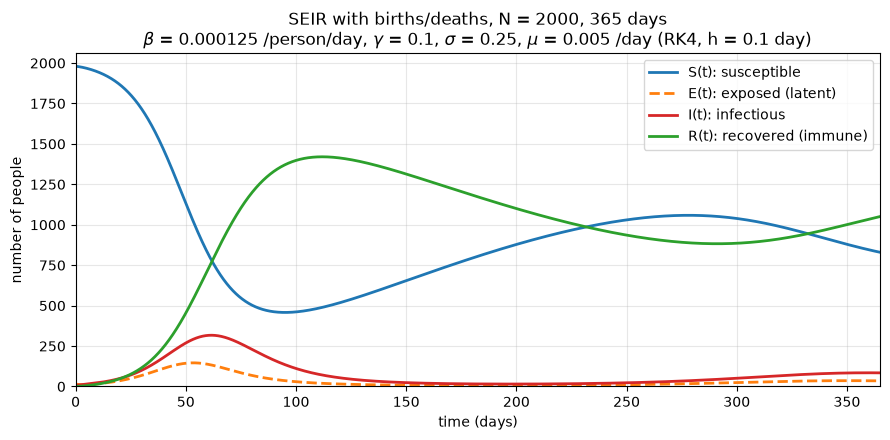

In [6]:
def plot_compartments(ax, t, Y, title):
    for name, series in zip("SEIR", Y.T):
        ax.plot(t, series, color=COLORS[name], ls=STYLES[name], lw=2, label=LABELS[name])
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, N * 1.03)
    ax.set_xlabel("time (days)"); ax.set_ylabel("number of people")
    ax.set_title(title); ax.grid(alpha=0.3)

param_str = (rf"$\beta$ = {beta:.3g} /person/day, $\gamma$ = {gamma}, $\sigma$ = {sigma}, "
             rf"$\mu$ = {mu} /day (RK4, h = {h} day)")

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_compartments(ax, t1, Y1, f"SEIR with births/deaths, N = {N}, 365 days\n{param_str}")
ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig("figures/partD_seir_365days.png", dpi=150); plt.show()

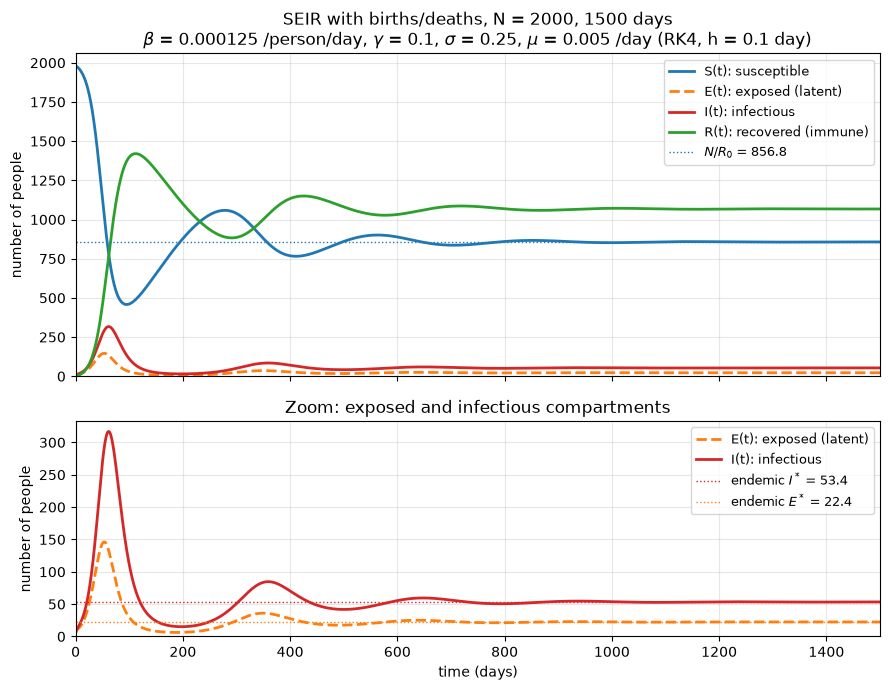

In [7]:
# Endemic equilibrium (derived in D(iv)); drawn here as reference lines
R0     = beta * N * sigma / ((sigma + mu) * (gamma + mu))
S_eq   = N / R0
I_eq   = mu * (N - S_eq) / (beta * S_eq)
E_eq   = (gamma + mu) * I_eq / sigma
R_eq   = gamma * I_eq / mu

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
plot_compartments(ax1, t2, Y2, f"SEIR with births/deaths, N = {N}, 1500 days\n{param_str}")
ax1.axhline(S_eq, color=COLORS["S"], ls=":", lw=1, label=f"$N/R_0$ = {S_eq:.1f}")
ax1.legend(loc="upper right", fontsize=9); ax1.set_xlabel("")

# Lower panel: same units (people), zoomed onto the small compartments E and I
for name, series in (("E", E), ("I", I)):
    ax2.plot(t2, series, color=COLORS[name], ls=STYLES[name], lw=2, label=LABELS[name])
ax2.axhline(I_eq, color=COLORS["I"], ls=":", lw=1, label=f"endemic $I^*$ = {I_eq:.1f}")
ax2.axhline(E_eq, color=COLORS["E"], ls=":", lw=1, label=f"endemic $E^*$ = {E_eq:.1f}")
ax2.set_ylim(0, 1.05 * I.max()); ax2.set_xlim(0, t_long)
ax2.set_xlabel("time (days)"); ax2.set_ylabel("number of people")
ax2.set_title("Zoom: exposed and infectious compartments"); ax2.legend(loc="upper right", fontsize=9)
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/partD_seir_1500days.png", dpi=150); plt.show()

### Is $h = 0.1$ day still accurate for 1500 days?

The runs are ~10× longer than in Part B, and the slow oscillations are sensitive to phase errors, so the step size is
re-checked: RK4 is run with $h = 0.8,\,0.4,\,0.2,\,0.1,\,0.05$ and compared with a reference RK4 run at $h=0.0125$ and,
independently, with SciPy's `solve_ivp` (DOP853, tight tolerances).

In [8]:
h_ref = 0.0125
t_ref, Y_ref = simulate(seir_rhs, y0, t_long, h_ref, params)

hs, errs = [0.8, 0.4, 0.2, 0.1, 0.05], []
for hh in hs:
    _, Y_h = simulate(seir_rhs, y0, t_long, hh, params)
    stride = int(round(hh / h_ref))
    errs.append(np.abs(Y_h - Y_ref[::stride]).max())

print(" h (day)   max error over 1500 days (people)   observed order log2(e(2h)/e(h))")
for i, (hh, e) in enumerate(zip(hs, errs)):
    order = "" if i == 0 else f"{np.log2(errs[i-1] / e):.2f}"
    print(f"  {hh:5.3f}      {e:.3e}                          {order}")

# Independent check against SciPy (verification only)
sol = solve_ivp(lambda t, y: seir_rhs(t, y, params), (0, t_long), y0, method="DOP853",
                t_eval=t2, rtol=1e-12, atol=1e-10)
err_scipy = np.abs(sol.y.T - Y2).max()
print(f"\nRK4 (h = {h}) vs solve_ivp DOP853: max |difference| = {err_scipy:.2e} people over 1500 days")
assert err_scipy < 1e-3

# Stability: RK4 is stable for real negative h*lambda down to about -2.79.
def seir_jacobian(y, p):
    S_, E_, I_, R_ = y
    b, s, g, m = p["beta"], p["sigma"], p["gamma"], p["mu"]
    return np.array([[-b*I_ - m, 0,        -b*S_,   0],
                     [ b*I_,    -(s + m),   b*S_,   0],
                     [ 0,        s,        -(g + m), 0],
                     [ 0,        0,         g,     -m]])
lam_max = max(np.abs(np.linalg.eigvals(seir_jacobian(y, params))).max() for y in Y2[::100])
print(f"largest |eigenvalue| of the Jacobian along the trajectory = {lam_max:.3f} /day"
      f"  ->  h*|lambda| = {h*lam_max:.3f}  (far inside RK4's stability limit ~2.8)")

 h (day)   max error over 1500 days (people)   observed order log2(e(2h)/e(h))
  0.800      4.587e-04                          
  0.400      2.473e-05                          4.21
  0.200      1.437e-06                          4.10
  0.100      8.661e-08                          4.05
  0.050      5.296e-09                          4.03

RK4 (h = 0.1) vs solve_ivp DOP853: max |difference| = 7.25e-07 people over 1500 days
largest |eigenvalue| of the Jacobian along the trajectory = 0.440 /day  ->  h*|lambda| = 0.044  (far inside RK4's stability limit ~2.8)


---
## D(iii) Epidemic waves

**How peaks are detected.**
1. **Candidate peaks** = grid points where $I$ is larger than its left neighbour and at least as large as its right neighbour.
2. Each peak is **refined** below the grid resolution with a parabola through the three surrounding points (as in Part C).
3. Each peak gets a **prominence** = peak height minus the lowest value of $I$ since the previous peak (the trough that
   separates it from the previous wave). Maxima with prominence below `NOISE_TOL` people would be round-off ripples; RK4 on
   this smooth problem produces none, but the guard makes the method safe if parameters are changed.
4. A peak counts as a **distinct epidemic wave** if its prominence is at least `MIN_REL_PROM` (20 %) of its own height,
   i.e. infections clearly fell and then clearly rose again. Smaller maxima are reported as
   **damped oscillations** around the endemic equilibrium $I^*$ (they are real features of the ODE, not numerical noise, but
   they are not separate outbreaks).

**Wave size** is reported two ways: the peak number of simultaneously infectious people, and the number of new infections
in the wave, $\int \beta S I\,dt$, integrated from the trough before the peak to the trough after it.

In [9]:
NOISE_TOL    = 1e-6     # people: maxima less prominent than this are treated as numerical noise
MIN_REL_PROM = 0.20     # prominence / peak height needed to call a maximum a distinct wave

def detect_waves(t, Y, p, noise_tol=NOISE_TOL, min_rel_prom=MIN_REL_PROM):
    S_, E_, I_, R_ = Y.T
    dt = t[1] - t[0]
    peaks = np.where((I_[1:-1] > I_[:-2]) & (I_[1:-1] >= I_[2:]))[0] + 1
    incidence = p["beta"] * S_ * I_                       # new infections per day (S -> E)
    waves, start = [], 0
    for n, k in enumerate(peaks):
        y1, y2, y3 = I_[k-1:k+2]
        d = 0.5 * (y1 - y3) / (y1 - 2*y2 + y3)            # parabolic refinement (offset in steps)
        trough_before = start + int(np.argmin(I_[start:k+1]))
        end = peaks[n+1] if n + 1 < len(peaks) else len(t) - 1
        trough_after = k + int(np.argmin(I_[k:end+1]))
        prom = y2 - I_[trough_before]
        if prom < noise_tol:
            continue
        seg = slice(trough_before, trough_after + 1)
        waves.append({"t_peak": t[k] + d*dt, "I_peak": y2 - 0.25*(y1 - y3)*d,
                      "t_trough_before": t[trough_before], "I_trough_before": I_[trough_before],
                      "prominence": prom, "rel_prom": prom / y2,
                      "new_infections": np.sum(0.5 * (incidence[seg][1:] + incidence[seg][:-1]) * dt),  # trapezoid rule
                      "window": (t[trough_before], t[trough_after]),
                      "S_at_peak": S_[k],
                      "kind": "epidemic wave" if prom / y2 >= min_rel_prom else "damped oscillation"})
        start = k
    return waves

def print_waves(waves, label):
    print(f"--- {label} ---")
    print(" #   peak day   peak I   preceding trough (day, I)   prominence   new infections (window)            type")
    for n, w in enumerate(waves, 1):
        print(f"{n:2d}   {w['t_peak']:7.1f}  {w['I_peak']:7.2f}     day {w['t_trough_before']:6.1f}, I = {w['I_trough_before']:6.2f}"
              f"     {w['prominence']:6.2f} ({w['rel_prom']:4.0%})   {w['new_infections']:7.1f}"
              f" (days {w['window'][0]:.0f}-{w['window'][1]:.0f})   {w['kind']}")

waves_365  = detect_waves(t1, Y1, params)
waves_1500 = detect_waves(t2, Y2, params)
print_waves(waves_365,  "365-day run")
print_waves(waves_1500, "1500-day run")
print(f"\nendemic equilibrium I* = {I_eq:.2f}  (peak heights relative to I*: "
      + ", ".join(f"{w['I_peak']/I_eq:.2f}x" for w in waves_1500) + ")")
print("intervals between successive peaks (days):",
      np.round(np.diff([w["t_peak"] for w in waves_1500]), 1))

--- 365-day run ---
 #   peak day   peak I   preceding trough (day, I)   prominence   new infections (window)            type
 1      61.6   316.92     day    0.0, I =   5.00     311.92 ( 98%)    2181.8 (days 0-198)   epidemic wave
 2     359.2    84.76     day  197.5, I =  15.14      69.62 ( 82%)     893.5 (days 198-365)   epidemic wave
--- 1500-day run ---
 #   peak day   peak I   preceding trough (day, I)   prominence   new infections (window)            type
 1      61.6   316.92     day    0.0, I =   5.00     311.92 ( 98%)    2181.8 (days 0-198)   epidemic wave
 2     359.2    84.76     day  197.5, I =  15.14      69.62 ( 82%)    1674.9 (days 198-500)   epidemic wave
 3     648.1    59.56     day  500.1, I =  41.83      17.73 ( 30%)    1661.1 (days 500-792)   epidemic wave
 4     938.0    54.72     day  792.2, I =  50.60       4.13 (  8%)    1659.9 (days 792-1083)   damped oscillation
 5    1228.3    53.67     day 1082.9, I =  52.74       0.94 (  2%)    1660.7 (days 1083-1374)   d

In [10]:
# Cross-checks of the detection
# (a) SciPy's find_peaks with no thresholds finds the same maxima -> no hidden or spurious peaks
pk, props = find_peaks(I, prominence=0)
assert np.allclose(t2[pk], [round(w["t_peak"] / h) * h for w in waves_1500], atol=h)
print("scipy find_peaks:", [(round(t2[k], 1), round(I[k], 2)) for k in pk])

# (b) At a peak of I, dI/dt = 0  <=>  sigma*E = (gamma+mu)*I  (latency inflow = outflow)
for w in waves_1500:
    k = int(round(w["t_peak"] / h))
    print(f"day {t2[k]:7.1f}: sigma*E = {sigma*E[k]:7.3f}, (gamma+mu)*I = {(gamma+mu)*I[k]:7.3f} people/day")

# (c) Unlike SIR, the I-peak does NOT occur exactly when S = N/R0: E delays it.
j = int(np.argmax(S < S_eq))
print(f"\nS first falls below N/R0 = {S_eq:.1f} on day {t2[j]:.1f}; first I-peak on day {waves_1500[0]['t_peak']:.1f} "
      f"(S there = {waves_1500[0]['S_at_peak']:.1f})")

scipy find_peaks: [(61.6, 316.92), (359.2, 84.76), (648.1, 59.56), (938.0, 54.72), (1228.3, 53.67)]
day    61.6: sigma*E =  33.261, (gamma+mu)*I =  33.277 people/day
day   359.2: sigma*E =   8.901, (gamma+mu)*I =   8.900 people/day
day   648.1: sigma*E =   6.254, (gamma+mu)*I =   6.254 people/day
day   938.0: sigma*E =   5.746, (gamma+mu)*I =   5.746 people/day
day  1228.3: sigma*E =   5.636, (gamma+mu)*I =   5.636 people/day

S first falls below N/R0 = 856.8 on day 58.8; first I-peak on day 61.6 (S there = 782.4)


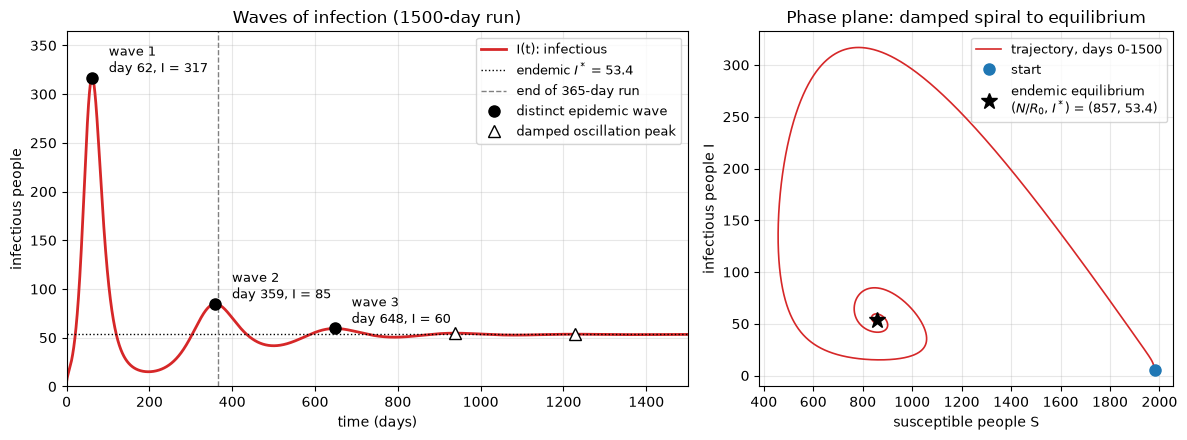

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [3, 2]})
ax1.plot(t2, I, color=COLORS["I"], lw=2, label="I(t): infectious")
ax1.axhline(I_eq, color="k", ls=":", lw=1, label=f"endemic $I^*$ = {I_eq:.1f}")
ax1.axvline(t_short, color="0.5", ls="--", lw=1, label="end of 365-day run")
for n, w in enumerate(waves_1500, 1):
    major = w["kind"] == "epidemic wave"
    ax1.plot(w["t_peak"], w["I_peak"], "o" if major else "^", color="k", mfc="k" if major else "w", ms=8)
    if major:
        ax1.annotate(f"wave {n}\nday {w['t_peak']:.0f}, I = {w['I_peak']:.0f}",
                     (w["t_peak"], w["I_peak"]), xytext=(12, 4), textcoords="offset points", fontsize=9)
ax1.plot([], [], "ko", ms=8, label="distinct epidemic wave")
ax1.plot([], [], "k^", mfc="w", ms=8, label="damped oscillation peak")
ax1.set_xlim(0, t_long); ax1.set_ylim(0, 1.15 * I.max())
ax1.set_xlabel("time (days)"); ax1.set_ylabel("infectious people")
ax1.set_title("Waves of infection (1500-day run)"); ax1.legend(loc="upper right", fontsize=9); ax1.grid(alpha=.3)

ax2.plot(S, I, color=COLORS["I"], lw=1.2, label="trajectory, days 0-1500")
ax2.plot(S[0], I[0], "o", color=COLORS["S"], ms=8, label="start")
ax2.plot(S_eq, I_eq, "k*", ms=12, label=f"endemic equilibrium\n($N/R_0$, $I^*$) = ({S_eq:.0f}, {I_eq:.1f})")
ax2.set_xlabel("susceptible people S"); ax2.set_ylabel("infectious people I")
ax2.set_title("Phase plane: damped spiral to equilibrium"); ax2.legend(loc="upper right", fontsize=9); ax2.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/partD_waves.png", dpi=150); plt.show()

**Pattern of infections.**
* **Wave 1 (main epidemic), peak day ≈ 61.6, ≈ 317 people infectious at once.** ≈ 2 180 new infections occur between day 0
  and the trough at day ≈ 198 (more than the 1 980 initial susceptibles, because births add 10 susceptibles per day). As in SIR, it overshoots: it drives $S$ far below the threshold $N/R_0$, so afterwards
  each case causes fewer than one new case and $I$ falls to ≈ 15 by day ≈ 198 (but never to zero).
* **Wave 2, peak day ≈ 359, ≈ 85 infectious.** During the trough, births refill $S$ until it again exceeds $N/R_0$,
  and the infection resurges. In the **365-day run** this second wave is caught only at its very top (peak on day ≈ 359,
  six days before the end), so the 365-day plot shows one large wave followed by the start of a second.
* **Wave 3, peak day ≈ 648, ≈ 60 infectious** — a smaller recurrence (prominence ≈ 30 % of its height).
* **Later maxima (days ≈ 938, ≈ 1228)** rise only ≈ 2.5 % and ≈ 0.6 % above $I^*$: these are **damped oscillations**,
  not new outbreaks.
* Peaks are spaced ≈ 290 days apart (298, 289, 290, 290), and each overshoot above $I^*$ shrinks to 12–22 % of the
  previous one, approaching the factor 0.225 predicted by linearization (D(iv)).
* Note on "new infections per wave": for waves 2–5 this is ≈ 1 660–1 675 per ≈ 290-day window, almost exactly the endemic
  background $\beta S^*I^*\times290\approx1\,658$. Later waves are therefore not extra infections on top of a quiet period;
  they are small fluctuations in a steady, continuing transmission.
  **Conclusion: several waves of decreasing size, not one wave and not sustained cycles — the system spirals into a stable
  endemic equilibrium** ($S\to N/R_0$, $I\to I^*\approx 53$), shown as the inward spiral in the phase plane.

---
## D(iv) Basic reproduction number and endemic equilibrium

**[analytical] Meaning of $R_0$.** One infected person introduced into a fully susceptible population ($S=N$):
* survives the latent period and becomes infectious with probability $\dfrac{\sigma}{\sigma+\mu}$ (otherwise dies first);
* is then infectious for a mean time $\dfrac{1}{\gamma+\mu}$ (ends by recovery or death), causing $\beta N$ infections per day.

$$R_0=\frac{\sigma}{\sigma+\mu}\cdot\frac{\beta N}{\gamma+\mu}=\frac{\beta N\sigma}{(\sigma+\mu)(\gamma+\mu)}.$$

**[analytical] Endemic equilibrium.** Setting all derivatives to 0 with $I^*>0$: from $dE/dt=0$ and $dI/dt=0$,
$\beta S^* I^*=(\sigma+\mu)E^*=(\sigma+\mu)(\gamma+\mu)I^*/\sigma$, so
$$S^*=\frac{(\sigma+\mu)(\gamma+\mu)}{\beta\sigma}=\frac{N}{R_0},\qquad
I^*=\frac{\mu(N-S^*)}{\beta S^*},\qquad E^*=\frac{(\gamma+\mu)I^*}{\sigma},\qquad R^*=\frac{\gamma I^*}{\mu}.$$

In [12]:
R0_SIR = beta * N / gamma                         # Part C
print(f"[analytical] R0 (SEIR + demography) = {R0:.4f}")
print(f"[analytical] R0 (SIR, Part C)       = {R0_SIR:.4f}")
print(f"             ratio = sigma/(sigma+mu) * gamma/(gamma+mu) = {sigma/(sigma+mu):.4f} * {gamma/(gamma+mu):.4f}"
      f" = {R0/R0_SIR:.4f}")

print(f"\n[analytical] N/R0 = {S_eq:.2f} people   (SIR: N/R0 = {N/R0_SIR:.0f})")
print(f"[numerical]  S(1500) = {S[-1]:.2f} people;  difference = {S[-1] - S_eq:+.3f}")
print(f"[numerical]  mean S over the last 290 days (one oscillation period) = {S[t2 >= t_long - 290].mean():.2f}")

print("\n           analytical equilibrium   RK4 at day 1500   difference")
for name, eq, val in zip("SEIR", (S_eq, E_eq, I_eq, R_eq), Y2[-1]):
    print(f"   {name}        {eq:10.3f}            {val:10.3f}        {val - eq:+.3f}")
print(f"   total    {S_eq + E_eq + I_eq + R_eq:10.3f}            {Y2[-1].sum():10.3f}")

[analytical] R0 (SEIR + demography) = 2.3343
[analytical] R0 (SIR, Part C)       = 2.5000
             ratio = sigma/(sigma+mu) * gamma/(gamma+mu) = 0.9804 * 0.9524 = 0.9337

[analytical] N/R0 = 856.80 people   (SIR: N/R0 = 800)
[numerical]  S(1500) = 856.92 people;  difference = +0.123
[numerical]  mean S over the last 290 days (one oscillation period) = 856.64

           analytical equilibrium   RK4 at day 1500   difference
   S           856.800               856.923        +0.123
   E            22.416                22.444        +0.029
   I            53.371                53.433        +0.062
   R          1067.414              1067.200        -0.214
   total      2000.000              2000.000


**[analytical] Linearization around the equilibrium** predicts the period and damping of the oscillations: the Jacobian
has a pair of complex eigenvalues $\lambda=-\delta\pm i\omega$, giving period $2\pi/\omega$ and an amplitude decaying by
the factor $e^{-\delta\cdot 2\pi/\omega}$ per cycle. The classic approximation $T\approx2\pi\sqrt{A\,G}$, with mean age at
infection $A=1/[\mu(R_0-1)]$ and disease generation time $G=1/(\sigma+\mu)+1/(\gamma+\mu)$, gives a similar period.

In [13]:
ev = np.linalg.eigvals(seir_jacobian([S_eq, E_eq, I_eq, R_eq], params))
osc = ev[np.argmax(ev.imag)]
T_lin, decay_lin = 2 * np.pi / osc.imag, np.exp(osc.real * 2 * np.pi / osc.imag)
A, G = 1 / (mu * (R0 - 1)), 1 / (sigma + mu) + 1 / (gamma + mu)
print("eigenvalues of the Jacobian at equilibrium:", np.round(ev, 5))
print(f"[analytical] period 2*pi/omega = {T_lin:.1f} days;  amplitude factor per cycle = {decay_lin:.3f}"
      f";  e-folding time 1/delta = {-1/osc.real:.0f} days")
print(f"[analytical] approximation 2*pi*sqrt(A*G) = 2*pi*sqrt({A:.1f} * {G:.2f}) = {2*np.pi*np.sqrt(A*G):.1f} days")

gaps = np.diff([w["t_peak"] for w in waves_1500])
excess = np.array([w["I_peak"] - I_eq for w in waves_1500])
print(f"[numerical]  intervals between peaks: {np.round(gaps, 1)} days")
print(f"[numerical]  ratio of successive peak excesses (I_peak - I*): {np.round(excess[1:] / excess[:-1], 3)}"
      "  -> approaches the linear prediction as the oscillations become small")

eigenvalues of the Jacobian at equilibrium: [-0.005  +0.j      -0.36141+0.j      -0.00513+0.02163j -0.00513-0.02163j]
[analytical] period 2*pi/omega = 290.5 days;  amplitude factor per cycle = 0.225;  e-folding time 1/delta = 195 days
[analytical] approximation 2*pi*sqrt(A*G) = 2*pi*sqrt(149.9 * 13.45) = 282.1 days
[numerical]  intervals between peaks: [297.7 288.8 289.9 290.3] days
[numerical]  ratio of successive peak excesses (I_peak - I*): [0.119 0.197 0.219 0.224]  -> approaches the linear prediction as the oscillations become small


**Comparison with Part C.** $R_0$ drops from 2.50 (SIR) to ≈ 2.33. The latent period alone does not change $R_0$ — it
only delays transmission — but with deaths, ≈ 2 % of exposed people die before becoming infectious
($\sigma/(\sigma+\mu)=0.980$) and the infectious period is cut short by death ($1/(\gamma+\mu)=9.52$ instead of 10 days).
Both effects come from $\mu$.

**Meaning of $N/R_0$.** $N/R_0$ is the **threshold number of susceptibles** at which the effective reproduction number
$R_t=R_0\,S/N$ equals 1: each case exactly replaces itself. With births, the epidemic settles where infections remove
susceptibles at the same rate as births add them, which forces $R_t=1$, i.e. $S^*=N/R_0\approx 857$. The simulation agrees:
$S(1500)\approx 856.9$ vs. $N/R_0=856.8$ (the remaining gap is the last, tiny oscillation). Epidemiologically:
* the fraction never infected in the long run, $1/R_0\approx 43\%$, is set by $R_0$ alone — not by $I_0$ or the timing of waves;
* $1-1/R_0\approx 57\%$ is the immune fraction needed to stop transmission (**herd-immunity / vaccination threshold**);
* if births push $S$ above $N/R_0$ the infection grows; if it is held below, it declines — this is why the waves recur.
In the SIR model of Part C, by contrast, $S$ falls *below* $N/R_0=800$ (to ≈ 214) and stays there, because nothing refills it.

---
## D(v) Effect of the exposed compartment and of births/deaths

These are **two different mechanisms**, so they are separated with a 2 × 2 comparison that switches each one on or off
(same $\beta,\gamma$, RK4 $h=0.1$, 1500 days). Without the exposed compartment, the 15 exposed people are counted as
infectious from the start ($I(0)=20$, which is the limit $\sigma\to\infty$).

model                              first peak day  first peak I  # peaks    I(1500)
SIR (no E, no births/deaths)                 33.0         475.0        1   1.64e-44
SEIR, no births/deaths (E only)              58.2         335.4        1    5.6e-38
SIR + births/deaths (mu only)                34.1         461.4        7       55.3
SEIR + births/deaths (Part D)                61.6         316.9        5       53.4


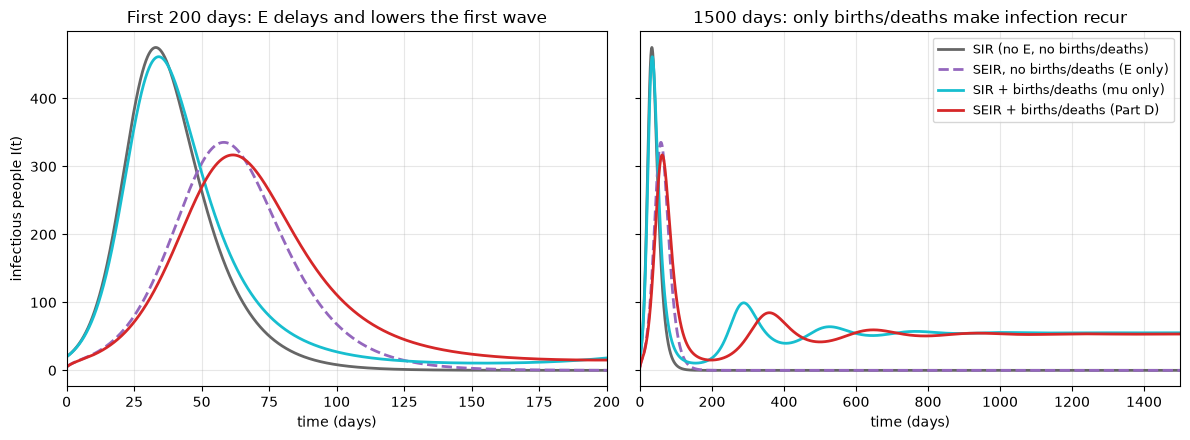

In [14]:
def sir_demog_rhs(t, y, p):
    # SIR with births and deaths (no exposed class) -- used only for this comparison
    S_, I_, R_ = y
    inf = p["beta"] * S_ * I_
    return np.array([p["mu"] * p["N"] - inf - p["mu"] * S_,
                     inf - (p["gamma"] + p["mu"]) * I_,
                     p["gamma"] * I_ - p["mu"] * R_])

y0_noE = np.array([1980.0, 20.0, 0.0])
p_noDemog = {**params, "mu": 0.0}
cases = {   # label: (I(t), rhs used)
    "SIR (no E, no births/deaths)":     simulate(sir_rhs,       y0_noE, t_long, h, params)[1][:, 1],
    "SEIR, no births/deaths (E only)":  simulate(seir_rhs,      y0,     t_long, h, p_noDemog)[1][:, 2],
    "SIR + births/deaths (mu only)":    simulate(sir_demog_rhs, y0_noE, t_long, h, params)[1][:, 1],
    "SEIR + births/deaths (Part D)":    I,
}
print(f"{'model':34s} {'first peak day':>14s} {'first peak I':>13s} {'# peaks':>8s} {'I(1500)':>10s}")
for lbl, Ic in cases.items():
    pk_c, _ = find_peaks(Ic)
    k = pk_c[0] if len(pk_c) else int(np.argmax(Ic))
    print(f"{lbl:34s} {t2[k]:14.1f} {Ic[k]:13.1f} {len(pk_c):8d} {Ic[-1]:10.3g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
styles = [("0.4", "-"), ("tab:purple", "--"), ("tab:cyan", "-"), (COLORS["I"], "-")]
for ax, xmax in zip(axes, (200, t_long)):
    for (lbl, Ic), (c, ls) in zip(cases.items(), styles):
        ax.plot(t2, Ic, color=c, ls=ls, lw=2, label=lbl)
    ax.set_xlim(0, xmax); ax.set_xlabel("time (days)"); ax.grid(alpha=.3)
axes[0].set_ylabel("infectious people I(t)")
axes[0].set_title("First 200 days: E delays and lowers the first wave")
axes[1].set_title("1500 days: only births/deaths make infection recur")
axes[1].legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig("figures/partD_mechanisms.png", dpi=150); plt.show()

**Exposed compartment (latency, $\sigma$) — changes *timing*, not *whether* infection persists.**
* Newly infected people spend on average $1/\sigma=4$ days unable to transmit, so each generation of cases takes longer
  ($\approx 1/\sigma+1/\gamma\approx 14$ days instead of 10). Early growth is slower and the first peak comes later
  (≈ day 58 instead of ≈ day 33 without deaths in the comparison runs) and is lower and broader (≈ 335 vs ≈ 475 people),
  because infections are spread over more time.
* The delay is also visible within the Part D run: $S$ drops below the threshold $N/R_0$ on day ≈ 58.8, but $I$ keeps rising
  until day ≈ 61.6, because people infected before the threshold are still leaving E and becoming infectious.
* Without deaths it does **not** change $R_0$ or the final size: the "E only" model ends exactly like SIR, with one wave
  and $I\to 0$.
* In the full model, E also acts as a **delay in the feedback** between susceptible depletion and infection, which makes
  the oscillations around equilibrium last longer (the period depends on $G$, which includes $1/\sigma$).

**Births and deaths (demographic turnover, $\mu$) — decide whether infection *persists or recurs*.**
* **Births** add $\mu N=10$ new susceptibles per day. After wave 1 has used up the susceptibles, births refill $S$; once
  $S$ again exceeds $N/R_0$, $R_t>1$ and a new wave starts. With at least $\approx 15$ infectious people in the trough,
  the chain of transmission is not broken, so the recurrence is possible.
* **Deaths** remove people from every compartment at the same rate. Removing recovered (immune) people and replacing
  them with susceptible newborns is what erodes population immunity; deaths of exposed/infectious people slightly
  reduce transmission (lower $R_0$, see D(iv)).
* Together, turnover provides a steady supply of susceptibles, so the system does not burn out as in SIR but settles at
  an **endemic equilibrium** with ≈ 53 people infectious at any time. Waves recur because the inflow of susceptibles is
  continuous while infections respond with a delay, so they repeatedly overshoot and undershoot the equilibrium; the
  oscillations are damped, so they shrink.

**Why $\mu=0.005$/day means a 200-day lifespan.** Each person dies at constant rate $\mu$, so lifetimes are exponentially
distributed with mean $1/\mu=1/0.005=200$ days ≈ 0.55 years. This unrealistically fast turnover replaces the whole
population within months, which is why recurring waves are visible within 1500 days.

mu = 1/(70 years) = 3.91e-05 /day
[analytical] R0 = 2.499, N/R0 = 800.4, endemic I* = 0.47 people, mean age at infection A = 46.7 years
[analytical] oscillation period = 8.4 years, damping e-folding time = 64 years


[numerical] first wave: day 58.2, I = 335.3;  minimum I afterwards = 5.0e-121 people (year 28.2)
[numerical] years after the first wave in which I(t) >= 1 person: []


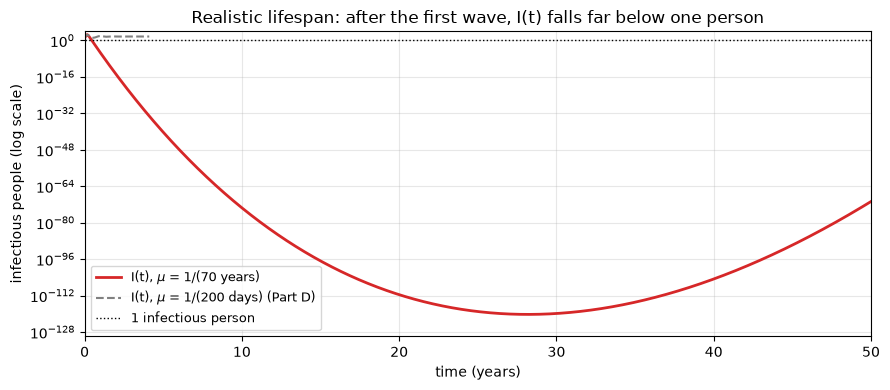

In [15]:
# Realistic human lifespan: 70 years
mu_real = 1 / (70 * 365)
p_real = {**params, "mu": mu_real}
R0_r = beta * N * sigma / ((sigma + mu_real) * (gamma + mu_real))
S_r = N / R0_r
I_r = mu_real * (N - S_r) / (beta * S_r)
ev_r = np.linalg.eigvals(seir_jacobian([S_r, (gamma + mu_real) * I_r / sigma, I_r, gamma * I_r / mu_real], p_real))
osc_r = ev_r[np.argmax(ev_r.imag)]
A_r = 1 / (mu_real * (R0_r - 1))
print(f"mu = 1/(70 years) = {mu_real:.2e} /day")
print(f"[analytical] R0 = {R0_r:.3f}, N/R0 = {S_r:.1f}, endemic I* = {I_r:.2f} people, "
      f"mean age at infection A = {A_r/365:.1f} years")
print(f"[analytical] oscillation period = {2*np.pi/osc_r.imag/365:.1f} years, damping e-folding time = {-1/osc_r.real/365:.0f} years")

years = 50
t_r, Y_r = simulate(seir_rhs, y0, years * 365, h, p_real)
I_real = Y_r[:, 2]
k1 = int(np.argmax(I_real)); after = t_r > 200
print(f"[numerical] first wave: day {t_r[k1]:.1f}, I = {I_real[k1]:.1f};  "
      f"minimum I afterwards = {I_real[after].min():.1e} people (year {t_r[after][np.argmin(I_real[after])]/365:.1f})")
print(f"[numerical] years after the first wave in which I(t) >= 1 person: "
      f"{np.unique(np.floor(t_r[after][I_real[after] >= 1] / 365)).astype(int).tolist()}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(t_r / 365, np.maximum(I_real, 1e-300), color=COLORS["I"], lw=2, label=r"I(t), $\mu$ = 1/(70 years)")
ax.semilogy(t2 / 365, I, color="0.5", lw=1.5, ls="--", label=r"I(t), $\mu$ = 1/(200 days) (Part D)")
ax.axhline(1, color="k", ls=":", lw=1, label="1 infectious person")
ax.set_xlabel("time (years)"); ax.set_ylabel("infectious people (log scale)")
ax.set_xlim(0, years); ax.set_ylim(1e-130, 1e4); ax.legend(loc="lower left", fontsize=9); ax.grid(alpha=.3)
ax.set_title("Realistic lifespan: after the first wave, I(t) falls far below one person")
plt.tight_layout(); plt.savefig("figures/partD_realistic_lifespan.png", dpi=150); plt.show()

**What changes with a realistic lifespan (≈ 70 years, $\mu\approx3.9\times10^{-5}$/day).**
* $R_0\to\beta N/\gamma\approx2.5$ and $N/R_0\to800$: deaths during latency/infection become negligible, so the model
  behaves like SIR on the time scale of one epidemic. The first wave is almost the SIR wave (peak ≈ day 58, ≈ 335 people).
* Births now add only ≈ 0.08 susceptibles per day, so refilling $S$ above $N/R_0$ takes **decades**. Close to equilibrium,
  linearization predicts ≈ 8-year cycles damped over ≈ 64 years. After a large first epidemic, which pushes $S$ far below
  $N/R_0$, the deterministic $I(t)$ keeps falling for ≈ 28 years before it starts to recover (see the figure).
* The endemic level is $I^*\approx0.47$ — **less than one person**. Between waves the deterministic $I(t)$ falls to
  ~$10^{-121}$ people, which in reality means the infection has **died out** (no one is left to transmit it).
  In a population of 2000 the disease would disappear after the first wave and return only if it were re-introduced from
  outside. Persistent endemic cycles (e.g. measles before vaccination) need large populations (hundreds of thousands)
  or a continual import of cases; a stochastic model would be needed to capture fade-out.
* Other realistic features left out here: age structure, waning immunity, seasonality in $\beta$, disease-related deaths,
  and births that do not exactly balance deaths.

---
## Summary

| check | result |
|---|---|
| initial conditions | $Y(0)=[1980,15,5,0]$ exactly, total 2000 |
| array dimensions | 365 d: $t$ (3651,), $Y$ (3651, 4); 1500 d: $t$ (15001,), $Y$ (15001, 4) |
| conservation | $\max|S+E+I+R-N|$ ~ $10^{-11}$ people (round-off); identity $dT/dt=\mu(N-T)$ verified |
| nonnegativity | all values ≥ 0 (strictly positive for $t>0$) |
| step size / convergence | observed RK4 order ≈ 4; error at $h=0.1$ far below 0.01 people; $h|\lambda|\ll2.8$ (stable) |
| independent solver | agrees with `solve_ivp` (DOP853) to well below $10^{-3}$ people over 1500 days |
| analytical relations | $S(1500)\approx N/R_0$; full endemic equilibrium matched; oscillation period and damping match the linearization; $\sigma E=(\gamma+\mu)I$ at each peak |
